# Bias in the Chicago Strategic Subject List

**Question:** how would the SSL have scored fictional people? Where do differences between groups in the scores come from?

**Approach:**
1. Create a model that reproduces the SSL score from its published predictors. The official algorithm isn't public.
2. Score the fictional profiles.
3. Compare who appears on the list with Chicago's population.
4. Measure how often each score raising factor appears in each group.
5. Break down the gap between groups' average scores by factor.

**Issues:**
- The model is an approximation, not the CPD algorithm.
- Everyone on the list had some police contact.
- About 78k rows are exact duplicates with no person ID. Results are shown both with and without them.
- Population shares are approximate 2020 Census figures.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from load_data import load_ssl, AGE_ORDER

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

df = load_ssl().dropna(subset=['predictor_rat_age_at_latest_arrest'])
df.shape

(398582, 46)

## 1. Model of the SSL score

A linear regression on the eight published predictors. Its coefficients can be read as **points added to the score per unit of each factor**.

In [3]:
PREDICTORS = {
    'predictor_rat_victim_shooting_incidents': 'Victim of shooting',
    'predictor_rat_victim_battery_or_assault': 'Victim of battery/assault',
    'predictor_rat_arrests_violent_offenses': 'Arrest: violent offense',
    'predictor_rat_gang_affiliation': 'Gang affiliation flag',
    'predictor_rat_narcotic_arrests': 'Arrest: narcotics',
    'predictor_rat_trend_in_criminal_activity': 'Trend in criminal activity',
    'predictor_rat_uuw_arrests': 'Arrest: unlawful use of weapon',
}
AGE_COL = 'predictor_rat_age_at_latest_arrest'

def design(frame):
    X = frame[list(PREDICTORS)].astype(float)
    ages = pd.get_dummies(frame[AGE_COL].astype(pd.CategoricalDtype(AGE_ORDER)), prefix='age', drop_first=True)
    return pd.concat([X, ages.astype(float)], axis=1)

X, y = design(df), df['ssl_score']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)
model = LinearRegression().fit(X_tr, y_tr)
print(f"Held-out R² = {model.score(X_te, y_te):.3f},  mean abs error = {np.abs(model.predict(X_te) - y_te).mean():.1f} points (scale 0-500)")
model = LinearRegression().fit(X, y)  # refit on all rows for the rest of the notebook
coefs = pd.Series(model.coef_, index=X.columns)

Held-out R² = 0.953,  mean abs error = 10.3 points (scale 0-500)


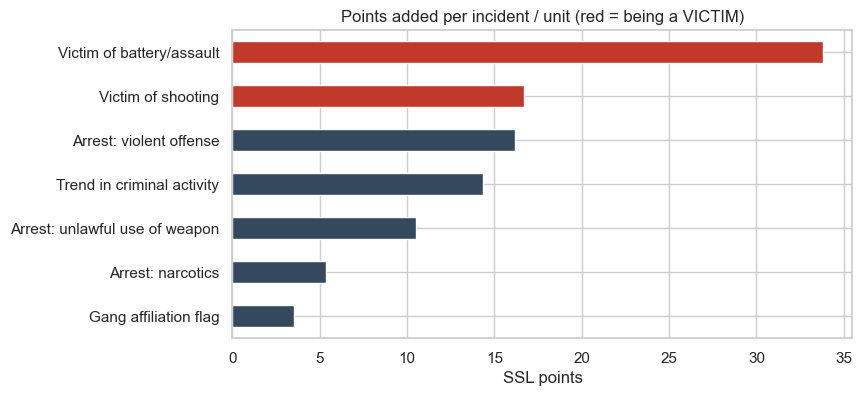

,points vs. under-20
less than 20,0.0
20-30,-32.0
30-40,-74.0
40-50,-118.0
50-60,-160.0
60-70,-202.0
70-80,-249.0


In [4]:
pts = coefs[list(PREDICTORS)].rename(PREDICTORS).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
pts.plot.barh(ax=ax, color=['#c0392b' if 'Victim' in i else '#34495e' for i in pts.index])
ax.set(title='Points added per incident / unit (red = being a VICTIM)', xlabel='SSL points')
plt.show()

age_pts = pd.Series([0] + list(coefs.filter(like='age_')), index=AGE_ORDER)
display(age_pts.round(0).to_frame('points vs. under-20'))

## 2. Fictional profiles and counterfactuals

None of these people are real. Each starts with **no counted arrests, no victimization, no gang flag**. We then change one thing at a time.

In [5]:
def score(age, **counts):
    row = pd.DataFrame([{**{k: 0 for k in PREDICTORS}, **counts, AGE_COL: age}])
    row[AGE_COL] = row[AGE_COL].astype(pd.CategoricalDtype(AGE_ORDER))
    return float(np.clip(model.predict(design(row))[0], 0, 500))

V_ASSAULT = 'predictor_rat_victim_battery_or_assault'
V_SHOOT = 'predictor_rat_victim_shooting_incidents'
NARC = 'predictor_rat_narcotic_arrests'
VIOLENT = 'predictor_rat_arrests_violent_offenses'

scenarios = {
    'Jordan, 19 — clean record':                      score('less than 20'),
    'Jordan, 19 — was mugged once (victim)':          score('less than 20', **{V_ASSAULT: 1}),
    'Jordan, 19 — was shot once (victim)':            score('less than 20', **{V_SHOOT: 1}),
    'Jordan, 19 — one narcotics arrest':              score('less than 20', **{NARC: 1}),
    'Jordan, 19 — one violent-offense arrest':        score('less than 20', **{VIOLENT: 1}),
    'Jordan, 19 — mugged twice + shot once (victim)': score('less than 20', **{V_ASSAULT: 2, V_SHOOT: 1}),
    'Maria, 34 — clean record':                       score('30-40'),
    'Dan, 47 — clean record':                         score('40-50'),
    'Dan, 47 — two violent arrests':                  score('40-50', **{VIOLENT: 2}),
}
profiles = pd.Series(scenarios).round(0).to_frame('estimated SSL score')
profiles['vs. list average'] = (profiles['estimated SSL score'] - df['ssl_score'].mean()).round(0)
profiles['percentile on list'] = [round((df['ssl_score'] < s).mean() * 100, 1) for s in profiles['estimated SSL score']]
profiles

,estimated SSL score,vs. list average,percentile on list
"Jordan, 19 — clean record",338.0,58.0,86.5
"Jordan, 19 — was mugged once (victim)",372.0,92.0,97.5
"Jordan, 19 — was shot once (victim)",355.0,75.0,94.5
"Jordan, 19 — one narcotics arrest",344.0,64.0,90.2
"Jordan, 19 — one violent-offense arrest",354.0,74.0,94.1
"Jordan, 19 — mugged twice + shot once (victim)",422.0,142.0,99.6
"Maria, 34 — clean record",265.0,-15.0,35.1
"Dan, 47 — clean record",220.0,-60.0,16.8
"Dan, 47 — two violent arrests",253.0,-27.0,29.3


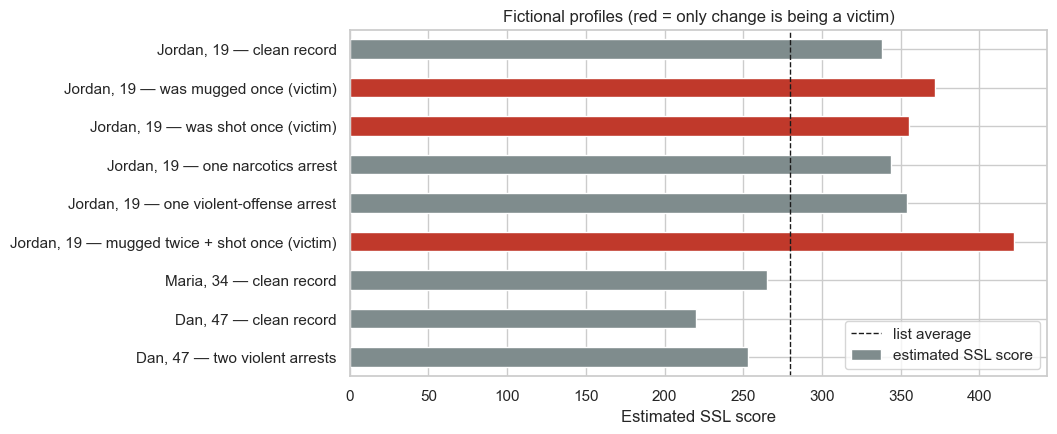

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
s = profiles['estimated SSL score'].iloc[::-1]
s.plot.barh(ax=ax, color=['#c0392b' if 'victim' in i else '#7f8c8d' for i in s.index])
ax.axvline(df['ssl_score'].mean(), ls='--', c='k', lw=1, label='list average')
ax.set(xlabel='Estimated SSL score', title='Fictional profiles (red = only change is being a victim)')
ax.legend(); plt.show()

## 3. Who is on the list vs. who lives in Chicago

In [7]:
GROUP = {'BLK': 'Black', 'WWH': 'Hispanic', 'WBH': 'Hispanic', 'WHI': 'White',
         'API': 'Asian/Pacific Islander', 'I': 'Other/Unknown', 'U': 'Other/Unknown'}
df['group'] = df['race_code_cd'].map(GROUP)

# Approximate 2020 Census shares for the City of Chicago (non-Hispanic for each race)
census = pd.Series({'Black': 28.7, 'Hispanic': 29.8, 'White': 31.4,
                    'Asian/Pacific Islander': 6.9, 'Other/Unknown': 3.2})

rep = pd.DataFrame({
    'share of list %': df['group'].value_counts(normalize=True).mul(100),
    'share of list (deduped) %': df.drop_duplicates()['group'].value_counts(normalize=True).mul(100),
    'share of Chicago %': census,
})
rep['over/under-representation (x)'] = rep['share of list %'] / rep['share of Chicago %']
rep.round(2)

,share of list %,share of list (deduped) %,share of Chicago %,over/under-representation (x)
Black,52.13,57.87,28.7,1.82
Hispanic,25.51,23.52,29.8,0.86
White,20.65,16.78,31.4,0.66
Asian/Pacific Islander,1.16,1.22,6.9,0.17
Other/Unknown,0.55,0.61,3.2,0.17


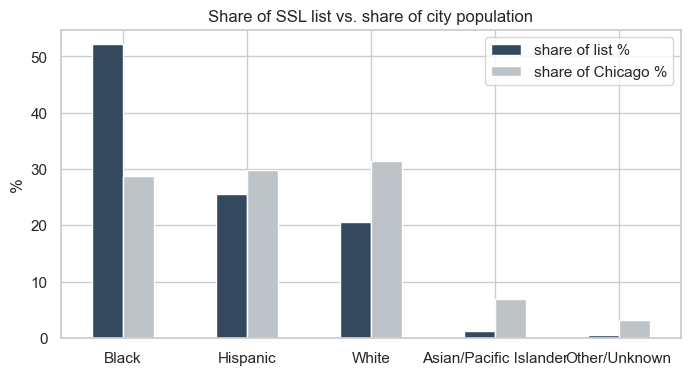

In [8]:
ax = rep[['share of list %', 'share of Chicago %']].plot.bar(figsize=(8, 4), rot=0, color=['#34495e', '#bdc3c7'])
ax.set(ylabel='%', title='Share of SSL list vs. share of city population'); plt.show()

## 4. How often each score-raising factor appears, by group

If one group's average score is higher, is it because of *arrests*, because of *being victimized*, or because of *age*?

In [9]:
main = ['Black', 'Hispanic', 'White']
d = df[df['group'].isin(main)]
prev = d.groupby('group')[list(PREDICTORS)].apply(lambda g: (g > 0).mean() * 100).rename(columns=PREDICTORS).T
under30 = d.groupby('group')[AGE_COL].apply(lambda s: s.isin(['less than 20', '20-30']).mean() * 100)
prev.loc['Age under 30 at latest arrest'] = under30
prev.round(1).rename_axis('% of people with factor')

group,Black,Hispanic,White
% of people with factor,,,
Victim of shooting,3.0,1.0,0.2
Victim of battery/assault,4.6,2.3,0.9
Arrest: violent offense,13.1,6.1,4.3
Gang affiliation flag,23.3,13.6,3.0
Arrest: narcotics,27.9,15.1,17.2
Trend in criminal activity,40.6,41.6,44.6
Arrest: unlawful use of weapon,4.6,1.9,1.0
Age under 30 at latest arrest,52.9,53.4,47.8


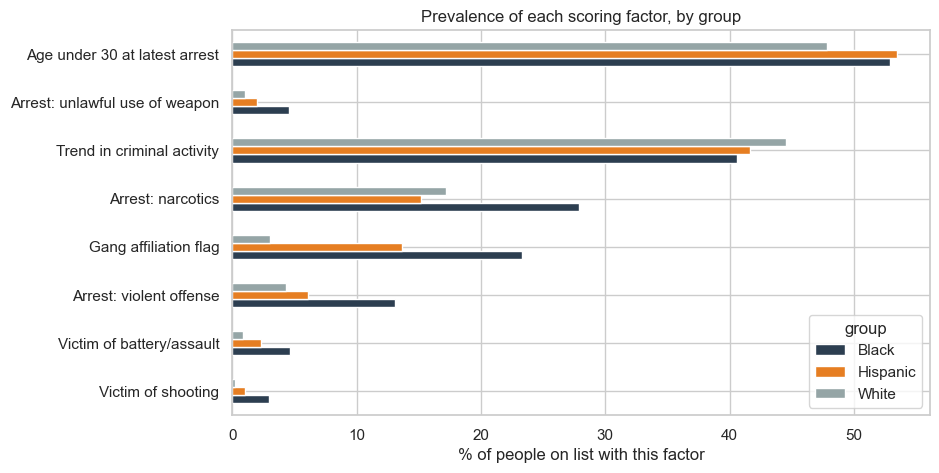

In [10]:
ax = prev.plot.barh(figsize=(9, 5), color=['#2c3e50', '#e67e22', '#95a5a6'])
ax.set(xlabel='% of people on list with this factor', title='Prevalence of each scoring factor, by group'); plt.show()

## 5. What is the score gap between groups

The gap is split factor by factor: **gap from factor = points per unit × (group average − White average)**. The leftover part (*residual*) is the gap the predictors don't explain. That would be any direct effect of race.

In [11]:
Xd = design(d)
d = d.assign(pred=model.predict(Xd), resid=d['ssl_score'] - model.predict(Xd))
means = Xd.groupby(d['group']).mean()
contrib = (means - means.loc['White']).mul(coefs)

def label(c):
    return PREDICTORS.get(c, 'Age at latest arrest')
contrib = contrib.T.groupby(label).sum().T
contrib['Unexplained (residual)'] = d.groupby('group')['resid'].mean() - d.loc[d.group == 'White', 'resid'].mean()

gap = d.groupby('group')['ssl_score'].mean() - d.loc[d.group == 'White', 'ssl_score'].mean()
summary = contrib.round(1)
summary['TOTAL gap vs White'] = gap.round(1)
summary.drop('White')

,Age at latest arrest,Arrest: narcotics,Arrest: unlawful use of weapon,Arrest: violent offense,Gang affiliation flag,Trend in criminal activity,Victim of battery/assault,Victim of shooting,Unexplained (residual),TOTAL gap vs White
group,,,,,,,,,,
Black,6.1,1.3,0.4,1.9,0.7,-0.6,1.4,0.5,0.9,12.6
Hispanic,11.9,-0.1,0.1,0.4,0.4,-0.3,0.5,0.2,0.4,13.5


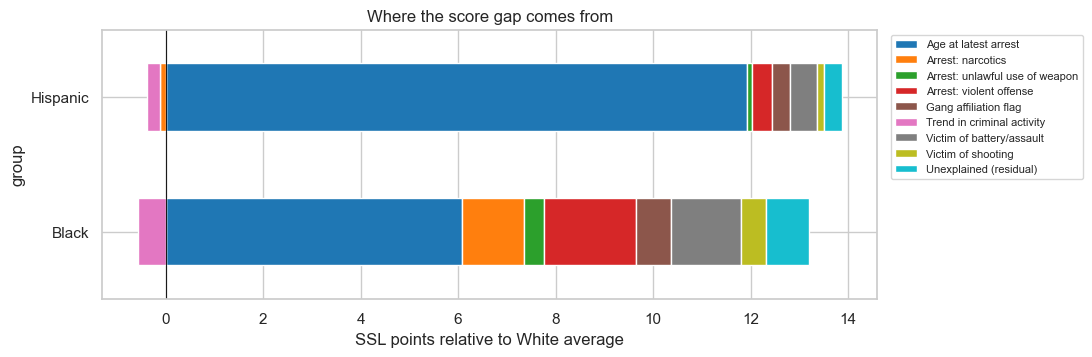

In [12]:
ax = contrib.drop('White').plot.barh(stacked=True, figsize=(10, 3.5), colormap='tab10')
ax.axvline(0, c='k', lw=0.8)
ax.set(xlabel='SSL points relative to White average', title='Where the score gap comes from')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8); plt.show()

## 6. Same record, different race?

People with identical inputs (same age band, all predictors zero) are compared directly across groups.

In [13]:
zero = d[(d[list(PREDICTORS)] == 0).all(axis=1)]
zero.pivot_table(index=AGE_COL, columns='group', values='ssl_score', aggfunc='mean', observed=True).round(1)

group,Black,Hispanic,White
predictor_rat_age_at_latest_arrest,,,
less than 20,339.6,336.0,335.8
20-30,307.1,304.8,305.1
30-40,265.5,265.0,264.6
40-50,220.8,222.2,219.5
50-60,177.9,178.4,178.1
60-70,136.3,135.9,136.0
70-80,91.5,95.5,88.2


## 7. Geography

The 15 community areas with the most people on the list. Location is missing for about 43% of rows.

In [14]:
geo = (df.dropna(subset=['community_area'])
         .groupby('community_area')
         .agg(people=('ssl_score', 'size'), avg_score=('ssl_score', 'mean'),
              pct_black=('group', lambda s: (s == 'Black').mean() * 100),
              pct_victim=(V_ASSAULT, lambda s: (s > 0).mean() * 100))
         .sort_values('people', ascending=False))
geo.head(15).round(1)

,people,avg_score,pct_black,pct_victim
community_area,,,,
AUSTIN,17897,282.2,84.1,5.5
HUMBOLDT PARK,9174,281.3,58.4,5.4
NORTH LAWNDALE,8626,281.4,86.8,6.1
WEST GARFIELD PARK,7825,274.2,87.4,5.4
NEAR WEST SIDE,7809,273.8,62.5,3.5
WEST ENGLEWOOD,6807,284.8,96.0,7.2
NEAR NORTH SIDE,6550,282.4,54.3,2.9
AUBURN GRESHAM,6359,284.4,97.1,6.4
ENGLEWOOD,6268,288.0,97.0,6.8


## Findings

1. **Age decides most of the score.** A fictional 19-year-old with no counted arrests, no victimization and no gang attachment scores around a **338**. That's higher than 86% of people on the list, many of whom have arrest records. A clean 47-year-old scores about 220. The difference in age changes the score by roughly 40 points. Every arrest factor adds about 5–16 points per incident.

2. **Being a victim raises the score more than committing violence.** One battery/assault *victimization* adds about **34 points**. One *arrest for a violent offense* adds about **16**. Being shot adds about 17. A fictional teenager who was mugged twice and shot once, and never arrested for anything counted, lands at about 422. That puts them in the top 1% of the list.

3. **The bigest disparity is who is on the list, not the score once you're on it.** Black people make up about 29% of the city but **52% of the list** (58% after removing duplicate rows), about 1.8–2x their share. White and Asian residents are under-represented.

4. **Race has almost no direct effect on the score.** People with identical inputs score the same within about 1–4 points whatever their race (section 6). After controlling for the predictors, the unexplained gap is under 1 point. Black and Hispanic people's average scores are only about 13 points above White people's. Half or more of that comes from being younger at their latest arrest.

5. **The disparity enters through the inputs.** Among people on the list:
   - Black people are about **15x** as likely as White people to be recorded as shooting victims (3.0% vs 0.2%).
   - About **5x** as likely to be recorded as assault victims.
   - About **8x** as likely to carry a gang-affiliation flag.
   - About **3x** as likely to have a violent-offense arrest.

   Narcotics arrests are an exception: White people on the list (17%) have them about as often as Hispanic people (15%). That points to who gets policed for drugs, not who uses them.

6. **Geography.** The community areas with the most people on the list are on the West and South Sides (Austin, North Lawndale, Englewood, Auburn Gresham, …), mostly 70–97% Black. They also have the highest victimization rates (5–7%), compared with about 2.5–3% in the Loop and the Near North Side.

**Conclusion:** the formula doesn't use race, but it inherits racial disparities through arrest records, gang flags and victimization. It also rewards youth and being a crime victim with higher risk scores. A law-abiding young person from a heavily policed neighborhood who has been victimized could unfortunately score in the top few percent.

